# Moneyball V8: Comprehensive Model with Full Evaluation

**Competition:** SCTPDSAI-M3-DS2F Coaching — MoneyBall Analytics
**Metric:** MAE (Mean Absolute Error) — lower is better

## What's New in V8

This notebook addresses all remaining gaps from the course Participant Notes:

| Gap | Solution |
|---|---|
| ElasticNet not tested | Test ElasticNet (L1+L2) with multiple L1 ratios |
| Silhouette scores missing | Proper K-Means cluster evaluation |
| PCA 2D/3D visualization | Scatter plots of teams in PCA space |
| RMSE / R² not reported | Full evaluation metrics for all models |
| Actual vs predicted plots | Diagnostic plots for best model |
| Residual analysis | Residual distribution and patterns |

## Model Progression

| Version | Key Idea | CV MAE |
|---|---|---|
| V1 (01_Ridge) | 121 sabermetric features | 2.720 |
| V5 | Per-game normalisation | 2.716 |
| V6 | Era z-score normalisation | 2.709 |
| V7 | Huber regression (outlier-robust) | 2.696 |
| **V8** | ElasticNet + full evaluation | ? |


## 1. Setup & Data Loading

Load training (1,812 team-seasons, 1904-2016) and test (453 team-seasons, 1892-2016) datasets. This notebook serves as the capstone — combining all feature engineering from V1-V6, testing all regression methods recommended in the course Participant Notes, and providing comprehensive evaluation diagnostics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV, HuberRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/data_year_team_franchise.csv")
test = pd.read_csv(f"{DATA_DIR}/predict_year_team_franchise.csv")

print(f"Training set: {train.shape[0]} team-seasons")
print(f"Test set:     {test.shape[0]} team-seasons")
print(f"Year range — Train: {train['yearID'].min()}-{train['yearID'].max()}")
print(f"Year range — Test:  {test['yearID'].min()}-{test['yearID'].max()}")

Training set: 1812 team-seasons
Test set:     453 team-seasons
Year range — Train: 1904-2016
Year range — Test:  1892-2016


## 2. Feature Engineering (V6 Base)

Reuse the proven V6 pipeline: per-game normalisation (÷G) to remove season-length confound, era z-scoring to remove era-level scoring environment shifts, and 50+ sabermetric features (OPS, WHIP, FIP, wOBA, Pythagorean expected wins, batting eye, pitch dominance, etc.).

In [2]:
def assign_era(df):
    df = df.copy()
    era_cols = [c for c in df.columns if c.startswith('era_')]
    era_labels = []
    for _, row in df.iterrows():
        found = False
        for ec in era_cols:
            if row[ec]:
                era_labels.append(ec)
                found = True
                break
        if not found:
            era_labels.append('era_unknown')
    df['era_label'] = era_labels
    return df

def engineer_features_v6(df, franch_counts=None, era_stats=None):
    df = df.copy()
    G = df['G']

    counting_stats = ['R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB',
                      'RA', 'ER', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA', 'BBA', 'SOA', 'E', 'DP']
    for s in counting_stats:
        df[f'{s}_pg'] = df[s] / G

    stats_to_zscore = counting_stats + [f'{s}_pg' for s in counting_stats] + ['ERA', 'FP']
    if era_stats is None:
        era_stats = {}
        for s in stats_to_zscore:
            era_stats[s] = df.groupby('era_label')[s].agg(['mean', 'std']).to_dict('index')

    for s in stats_to_zscore:
        z_vals = []
        for _, row in df.iterrows():
            era = row['era_label']
            if era in era_stats[s]:
                mean = era_stats[s][era]['mean']
                std = era_stats[s][era]['std']
                z_vals.append((row[s] - mean) / (std + 1e-6))
            else:
                z_vals.append(0)
        df[f'{s}_ez'] = z_vals

    Rpg, RApg = df['R_pg'], df['RA_pg']
    Hpg, ABpg, BBpg, SOpg = df['H_pg'], df['AB_pg'], df['BB_pg'], df['SO_pg']
    HRpg, B2pg, B3pg, SBpg = df['HR_pg'], df['2B_pg'], df['3B_pg'], df['SB_pg']
    HApg, HRApg, BBApg, SOApg = df['HA_pg'], df['HRA_pg'], df['BBA_pg'], df['SOA_pg']
    IPpg = df['IPouts_pg'] / 3
    ERpg = df['ER_pg']

    df['1B_pg'] = Hpg - B2pg - B3pg - HRpg
    df['TB_pg'] = df['1B_pg'] + 2*B2pg + 3*B3pg + 4*HRpg
    PApg = ABpg + BBpg
    df['BA']  = Hpg / (ABpg + 0.001)
    df['SLG'] = df['TB_pg'] / (ABpg + 0.001)
    df['OBP'] = (Hpg + BBpg) / (PApg + 0.001)
    df['OPS'] = df['OBP'] + df['SLG']
    df['ISO'] = df['SLG'] - df['BA']
    df['wOBA'] = (0.69*BBpg + 0.89*df['1B_pg'] + 1.27*B2pg + 1.62*B3pg + 2.10*HRpg) / (PApg + 0.001)
    df['BABIP'] = (Hpg - HRpg) / (ABpg - SOpg - HRpg + 0.001)
    df['K_pct']  = SOpg / (PApg + 0.001)
    df['BB_pct'] = BBpg / (PApg + 0.001)
    df['batting_eye'] = df['BB_pct'] - df['K_pct']
    df['RC_pg']  = (Hpg + BBpg) * df['TB_pg'] / (PApg + 0.001)
    df['SecA']   = (df['TB_pg'] - Hpg + BBpg + SBpg) / (ABpg + 0.001)
    df['power_speed'] = (2 * HRpg * SBpg) / (HRpg + SBpg + 0.001)
    df['BB_SO_ratio'] = BBpg / (SOpg + 0.001)

    df['WHIP'] = (BBApg + HApg) / (IPpg + 0.001)
    df['H9']   = HApg / (IPpg + 0.001) * 9
    df['HR9']  = HRApg / (IPpg + 0.001) * 9
    df['BB9']  = BBApg / (IPpg + 0.001) * 9
    df['SO9']  = SOApg / (IPpg + 0.001) * 9
    df['SO_BB_ratio']     = SOApg / (BBApg + 0.001)
    df['FIP']             = (13*HRApg + 3*BBApg - 2*SOApg) / (IPpg + 0.001) + 3.10
    df['BABIP_against']   = (HApg - HRApg) / (IPpg*3 - SOApg - HRApg + 0.001)
    df['pitch_dominance'] = SOApg / (HApg + BBApg + 0.001)
    df['pitch_resilience'] = df['SO9'] / (df['WHIP'] + 0.001)
    df['FIP_ERA_diff']    = df['FIP'] - df['ERA']

    df['run_diff_pg'] = Rpg - RApg
    R, RA = df['R'], df['RA']
    df['pyth_wins']     = R**2 / (R**2 + RA**2) * G
    df['pyth_wins_183'] = R**1.83 / (R**1.83 + RA**1.83) * G
    rpg_total = (R + RA) / G
    pexp = rpg_total ** 0.287
    df['pyth_wins_pat'] = R**pexp / (R**pexp + RA**pexp) * G
    df['pyth_pct']     = R**2 / (R**2 + RA**2)
    df['pyth_pct_pat'] = R**pexp / (R**pexp + RA**pexp)
    df['log_run_ratio'] = np.log(R / (RA + 1))
    df['run_diff_sq']   = (R - RA)**2 * np.sign(R - RA)
    df['R_above_RC']    = Rpg - df['RC_pg']
    df['run_support_era'] = Rpg / (df['ERA'] + 0.001)

    df['DER'] = 1 - ((HApg - HRApg) / (df['IPouts_pg'] + HApg - HRApg - SOApg + 0.001))
    df['UER_pg']  = RApg - ERpg
    df['UER_pct'] = df['UER_pg'] / (RApg + 0.001)

    df['R_vs_mlb']  = Rpg - df['mlb_rpg']
    df['RA_vs_mlb'] = RApg - df['mlb_rpg']
    df['R_ratio']   = Rpg / (df['mlb_rpg'] + 0.001)
    df['RA_ratio']  = RApg / (df['mlb_rpg'] + 0.001)
    league_era = df['mlb_rpg'] * 0.92
    df['ERA_plus'] = league_era / (df['ERA'] + 0.001) * 100
    df['FIP_plus'] = league_era / (df['FIP'] + 0.001) * 100
    df['OPS_plus'] = df['OPS'] / (df['mlb_rpg'] / 4.5) * 100
    df['R_above_avg']  = df['R_vs_mlb'] * G
    df['RA_below_avg'] = -df['RA_vs_mlb'] * G
    df['total_runs_above_avg'] = df['R_above_avg'] + df['RA_below_avg']
    df['team_quality'] = (df['OPS'] - df['WHIP']) * 100

    if franch_counts is not None:
        df['franch_freq'] = df['franchID'].map(franch_counts).fillna(1)
    else:
        franch_counts = df['franchID'].value_counts().to_dict()
        df['franch_freq'] = df['franchID'].map(franch_counts)

    return df, franch_counts, era_stats

# Build features
train = assign_era(train)
test = assign_era(test)
combined = pd.concat([train, test], ignore_index=True)
combined = assign_era(combined) if 'era_label' not in combined.columns else combined
counting_stats = ['R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB',
                  'RA', 'ER', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA', 'BBA', 'SOA', 'E', 'DP']
for s in counting_stats:
    combined[f'{s}_pg'] = combined[s] / combined['G']
stats_to_zscore = counting_stats + [f'{s}_pg' for s in counting_stats] + ['ERA', 'FP']
era_stats = {}
for s in stats_to_zscore:
    era_stats[s] = combined.groupby('era_label')[s].agg(['mean', 'std']).to_dict('index')

train_fe, franch_counts, _ = engineer_features_v6(train, era_stats=era_stats)
test_fe, _, _ = engineer_features_v6(test, franch_counts=franch_counts, era_stats=era_stats)
print(f"V6 base features — Train: {train_fe.shape}, Test: {test_fe.shape}")

V6 base features — Train: (1812, 170), Test: (453, 166)


## 3. Prepare Feature Matrix

Select V6-A features (per-game rates + era z-scores + sabermetrics, no raw counting stats). Handle infinities and missing values with median imputation. Separate indicator columns (era/decade dummies) from continuous features for selective scaling — indicators are left unscaled since they are already binary.

In [3]:
y = train_fe['W'].values
exclude = {'W', 'ID', 'yearID', 'teamID', 'franchID', 'year_label', 'decade_label', 'win_bins', 'era_label'}

for col_to_drop in ['era_label', 'decade_label']:
    if col_to_drop in train_fe.columns:
        train_fe[col_to_drop] = train_fe[col_to_drop].astype(str)
    if col_to_drop in test_fe.columns:
        test_fe[col_to_drop] = test_fe[col_to_drop].astype(str)

# V6-A feature set (best from V6): per-game + era z-scores + sabermetrics + indicators
raw_counting = set(counting_stats)
pg_cols = {f'{s}_pg' for s in counting_stats}
ez_cols = {c for c in train_fe.columns if c.endswith('_ez')}
saber_cols = {c for c in train_fe.columns if c not in exclude and c not in raw_counting
              and c not in pg_cols and c not in ez_cols
              and train_fe[c].dtype in ['int64', 'float64', 'bool']
              and not c.startswith(('era_', 'decade_'))}
indicator_cols = {c for c in train_fe.columns if c.startswith(('era_', 'decade_'))
                  and train_fe[c].dtype in ['bool', 'int64', 'float64']}

base_features = sorted(pg_cols | ez_cols | saber_cols | indicator_cols)
base_features = [c for c in base_features if c in train_fe.columns]

def prepare_data(train_df, test_df, feat_list):
    tr = train_df[feat_list].copy()
    te = test_df[feat_list].copy()
    for c in feat_list:
        if tr[c].dtype == 'bool':
            tr[c] = tr[c].astype(int)
            te[c] = te[c].astype(int)
    tr = tr.replace([np.inf, -np.inf], np.nan)
    te = te.replace([np.inf, -np.inf], np.nan)
    for c in feat_list:
        med = tr[c].median()
        tr[c] = tr[c].fillna(med)
        te[c] = te[c].fillna(med)
    return tr.values.astype(float), te.values.astype(float)

X_base, Xt_base = prepare_data(train_fe, test_fe, base_features)

oh_feats = [c for c in base_features if c.startswith(('era_', 'decade_'))]
ct_feats = [c for c in base_features if c not in oh_feats]
oh_idx = [base_features.index(c) for c in oh_feats]
ct_idx = [base_features.index(c) for c in ct_feats]

print(f"Base features: {len(base_features)} (Continuous: {len(ct_idx)}, Indicator: {len(oh_idx)})")

Base features: 140 (Continuous: 121, Indicator: 19)


## 4. PCA Visualization — Team Archetypes in 2D/3D

PCA reduces our 120+ continuous features into a few orthogonal components. Plotting teams in this space reveals natural archetypes and era clustering.


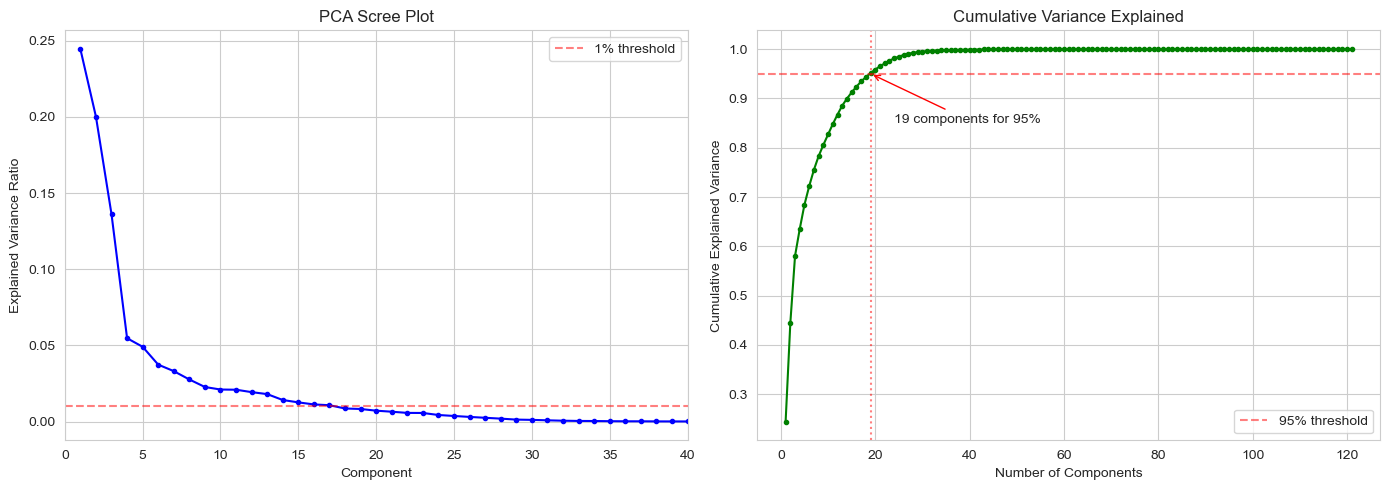

Components for 95% variance: 19
Top 5 components explain: 68.5%
Top 10 components explain: 82.7%


In [4]:
# Scale continuous features for PCA
sc_pca = StandardScaler()
X_cont = sc_pca.fit_transform(X_base[:, ct_idx])
Xt_cont = sc_pca.transform(Xt_base[:, ct_idx])

# Fit PCA
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_cont)

# Explained variance plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(pca_full.explained_variance_ratio_)+1),
             pca_full.explained_variance_ratio_, 'bo-', markersize=3)
axes[0].set_xlabel('Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('PCA Scree Plot')
axes[0].axhline(y=0.01, color='red', ls='--', alpha=0.5, label='1% threshold')
axes[0].legend()
axes[0].set_xlim(0, 40)

# Cumulative variance
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].plot(range(1, len(cumvar)+1), cumvar, 'go-', markersize=3)
axes[1].axhline(y=0.95, color='red', ls='--', alpha=0.5, label='95% threshold')
n95 = np.argmax(cumvar >= 0.95) + 1
axes[1].axvline(x=n95, color='red', ls=':', alpha=0.5)
axes[1].annotate(f'{n95} components for 95%', xy=(n95, 0.95), fontsize=10,
                xytext=(n95+5, 0.85), arrowprops=dict(arrowstyle='->', color='red'))
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Variance Explained')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Components for 95% variance: {n95}")
print(f"Top 5 components explain: {cumvar[4]*100:.1f}%")
print(f"Top 10 components explain: {cumvar[9]*100:.1f}%")

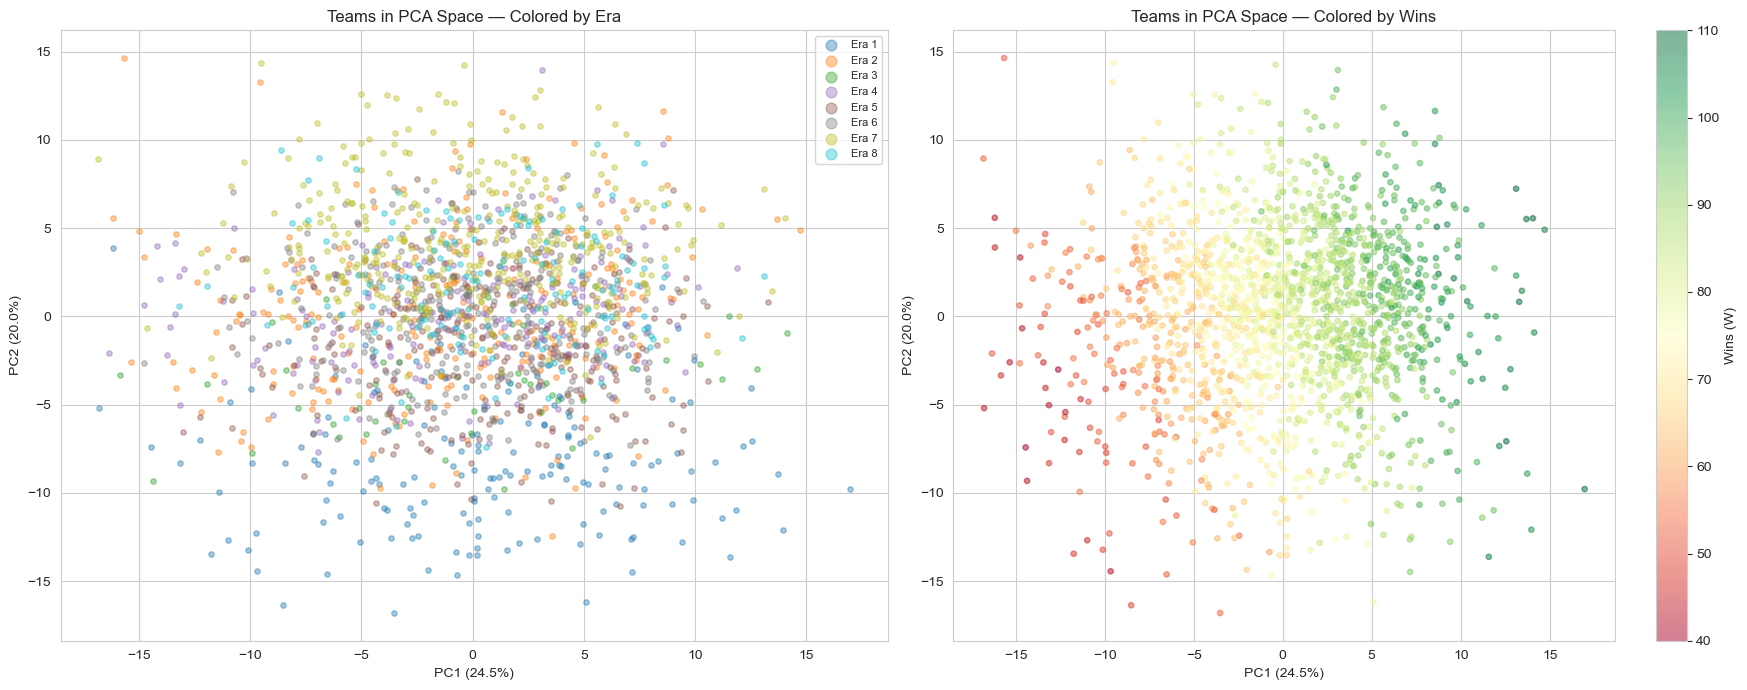

In [5]:
# 2D PCA — teams colored by era
era_cols_orig = [c for c in train.columns if c.startswith('era_')]
era_map = {}
for _, row in train.iterrows():
    for ec in era_cols_orig:
        if row[ec]:
            era_map[row.name] = ec.replace('era_', 'Era ')
            break
era_labels = pd.Series(era_map)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Color by era
era_order = sorted(era_labels.unique())
colors_era = plt.cm.tab10(np.linspace(0, 1, len(era_order)))
for i, era in enumerate(era_order):
    mask = era_labels == era
    axes[0].scatter(X_pca_full[mask, 0], X_pca_full[mask, 1],
                   c=[colors_era[i]], alpha=0.4, s=15, label=era)
axes[0].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].set_title('Teams in PCA Space — Colored by Era')
axes[0].legend(fontsize=8, markerscale=2)

# Color by wins
scatter = axes[1].scatter(X_pca_full[:, 0], X_pca_full[:, 1],
                          c=y, cmap='RdYlGn', alpha=0.5, s=15, vmin=40, vmax=110)
plt.colorbar(scatter, ax=axes[1], label='Wins (W)')
axes[1].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].set_title('Teams in PCA Space — Colored by Wins')

plt.tight_layout()
plt.show()

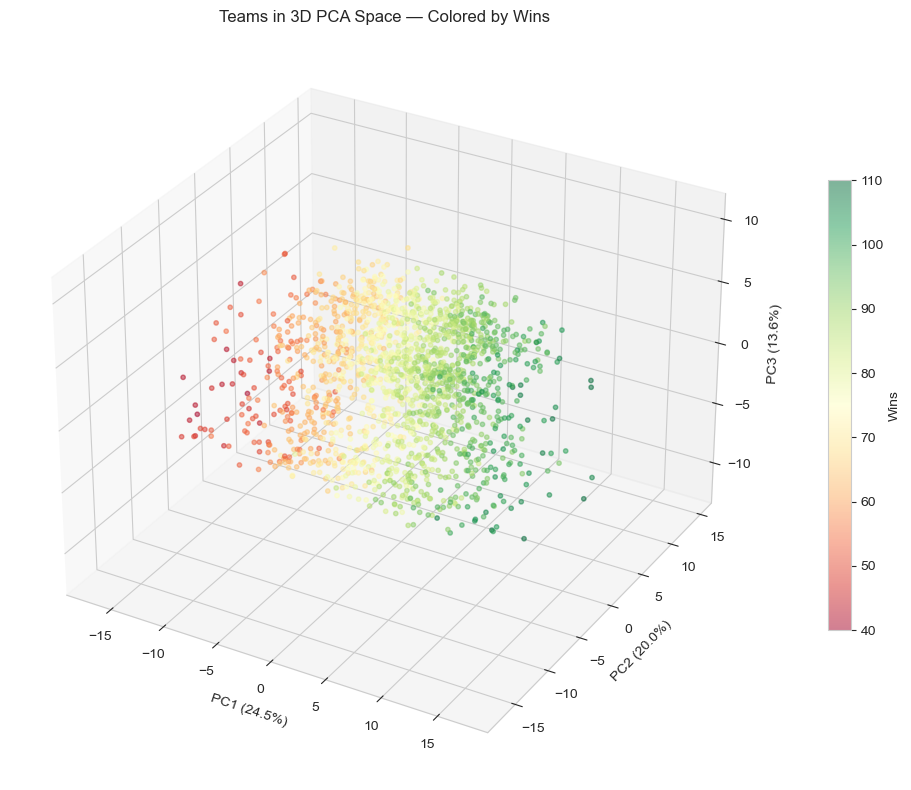

Top PCA Component Loadings:
Feature                   PC1      PC2      PC3
------------------------------------------------

PC1 — top 5 features by loading magnitude:
  pyth_wins_pat             +0.1755
  total_runs_above_avg      +0.1755
  pyth_pct_pat              +0.1753
  pyth_wins                 +0.1752
  run_diff_pg               +0.1752

PC2 — top 5 features by loading magnitude:
  TB_pg                     +0.1865
  SLG                       +0.1854
  OPS                       +0.1834
  RC_pg                     +0.1825
  wOBA                      +0.1821

PC3 — top 5 features by loading magnitude:
  K_pct                     +0.2076
  SO9                       +0.2058
  SOA_pg                    +0.2056
  pitch_resilience          +0.2054
  pitch_dominance           +0.2054


In [6]:
# 3D PCA plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(X_pca_full[:, 0], X_pca_full[:, 1], X_pca_full[:, 2],
                     c=y, cmap='RdYlGn', alpha=0.5, s=10, vmin=40, vmax=110)
ax.set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_zlabel(f'PC3 ({pca_full.explained_variance_ratio_[2]*100:.1f}%)')
ax.set_title('Teams in 3D PCA Space — Colored by Wins')
plt.colorbar(scatter, ax=ax, label='Wins', shrink=0.6)

plt.tight_layout()
plt.show()

# What do the top components represent?
print("Top PCA Component Loadings:")
print(f"{'Feature':<20} {'PC1':>8} {'PC2':>8} {'PC3':>8}")
print("-" * 48)
loadings = pd.DataFrame(pca_full.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=ct_feats)
for pc in ['PC1', 'PC2', 'PC3']:
    top = loadings[pc].abs().nlargest(5)
    print(f"\n{pc} — top 5 features by loading magnitude:")
    for feat, val in top.items():
        print(f"  {feat:<25} {loadings.loc[feat, pc]:+.4f}")

## 5. K-Means Clustering with Silhouette Analysis

Instead of just inertia, we use **silhouette scores** to find the optimal number of clusters.
The silhouette score measures how similar each point is to its own cluster vs the nearest other cluster.


k= 2  silhouette=0.1429  inertia=      184338
k= 3  silhouette=0.1302  inertia=      166042


k= 4  silhouette=0.1231  inertia=      153783
k= 5  silhouette=0.1207  inertia=      143965


k= 6  silhouette=0.1136  inertia=      136473
k= 7  silhouette=0.1029  inertia=      131553


k= 8  silhouette=0.1019  inertia=      127673
k= 9  silhouette=0.1045  inertia=      124170


k=10  silhouette=0.0998  inertia=      121048


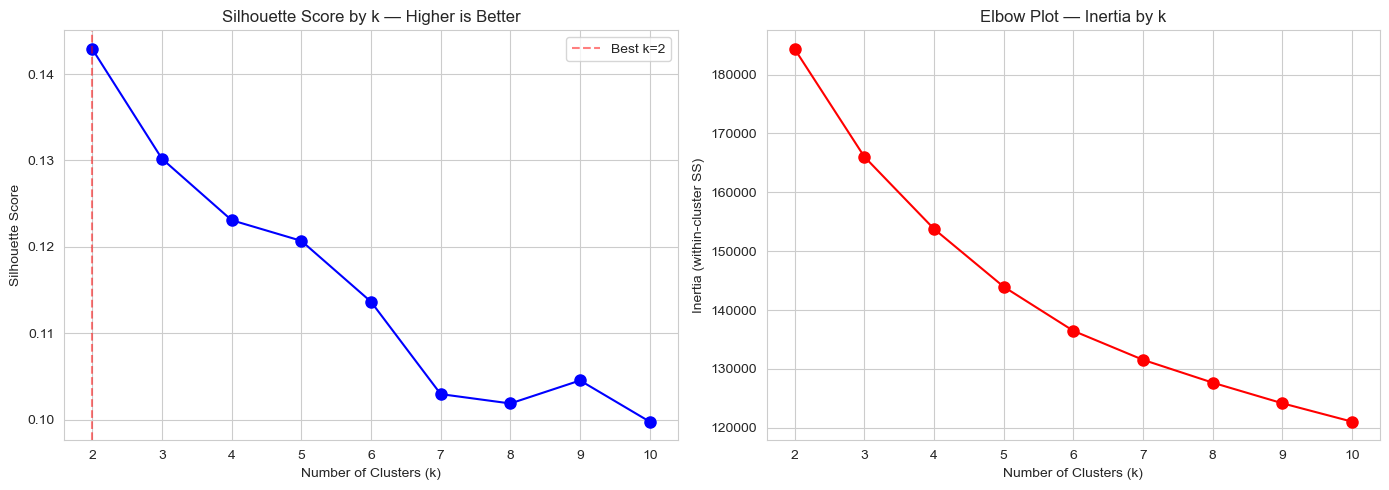


Best k by silhouette: 2 (score=0.1429)


In [7]:
# Silhouette analysis for k=2..10
sil_scores = []
inertias = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cont)
    sil = silhouette_score(X_cont, labels)
    sil_scores.append(sil)
    inertias.append(km.inertia_)
    print(f"k={k:2d}  silhouette={sil:.4f}  inertia={km.inertia_:>12.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Silhouette scores
axes[0].plot(list(k_range), sil_scores, 'bo-', markersize=8)
best_k = list(k_range)[np.argmax(sil_scores)]
axes[0].axvline(x=best_k, color='red', ls='--', alpha=0.5, label=f'Best k={best_k}')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Score by k — Higher is Better')
axes[0].legend()

# Elbow plot (inertia)
axes[1].plot(list(k_range), inertias, 'ro-', markersize=8)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Inertia (within-cluster SS)')
axes[1].set_title('Elbow Plot — Inertia by k')

plt.tight_layout()
plt.show()
print(f"\nBest k by silhouette: {best_k} (score={max(sil_scores):.4f})")

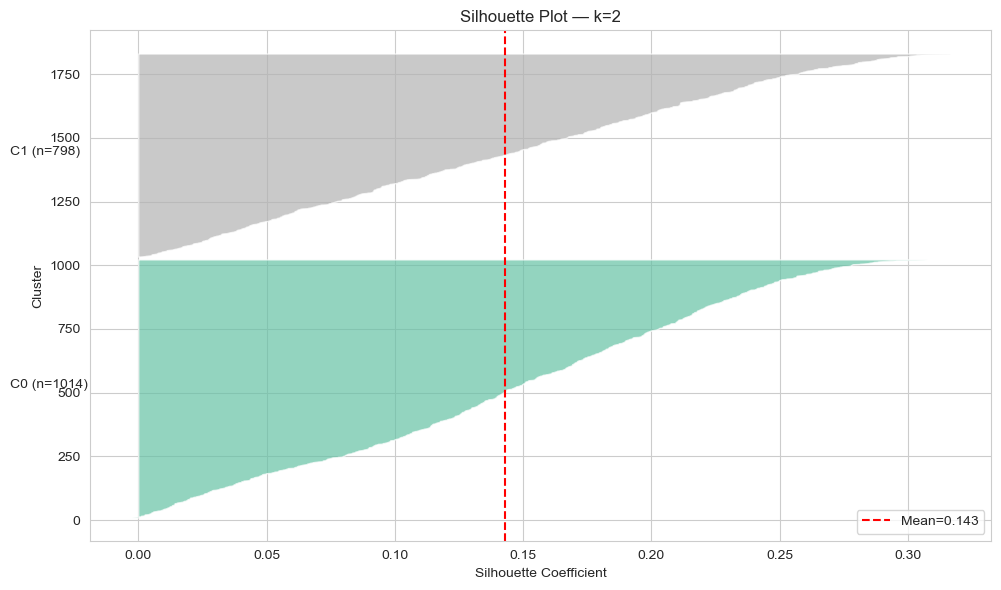


Cluster Profiles (scaled feature means):
          R_pg  HR_pg  SO_pg    ERA    OPS   WHIP   FIP  pyth_pct  run_diff_pg
cluster                                                                       
0        0.346  0.170 -0.016 -0.396  0.301 -0.456 -0.33     0.704        0.698
1       -0.440 -0.216  0.021  0.503 -0.383  0.580  0.42    -0.894       -0.887


In [8]:
# Silhouette plot for best k
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = km_best.fit_predict(X_cont)
sil_vals = silhouette_samples(X_cont, cluster_labels)

fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 10
colors_cl = plt.cm.Set2(np.linspace(0, 1, best_k))

for i in range(best_k):
    ith_sil = sil_vals[cluster_labels == i]
    ith_sil.sort()
    size_i = ith_sil.shape[0]
    y_upper = y_lower + size_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil, facecolor=colors_cl[i], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_i, f'C{i} (n={size_i})', fontsize=10)
    y_lower = y_upper + 10

ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster')
ax.set_title(f'Silhouette Plot — k={best_k}')
ax.axvline(x=silhouette_score(X_cont, cluster_labels), color='red', ls='--',
           label=f'Mean={silhouette_score(X_cont, cluster_labels):.3f}')
ax.legend()
plt.tight_layout()
plt.show()

# Show cluster means for key features
cluster_df = pd.DataFrame(X_cont, columns=ct_feats)
cluster_df['cluster'] = cluster_labels
key_feats = ['R_pg', 'HR_pg', 'SO_pg', 'ERA', 'OPS', 'WHIP', 'FIP', 'pyth_pct', 'run_diff_pg']
key_feats = [f for f in key_feats if f in ct_feats]
print("\nCluster Profiles (scaled feature means):")
print(cluster_df.groupby('cluster')[key_feats].mean().round(3).to_string())

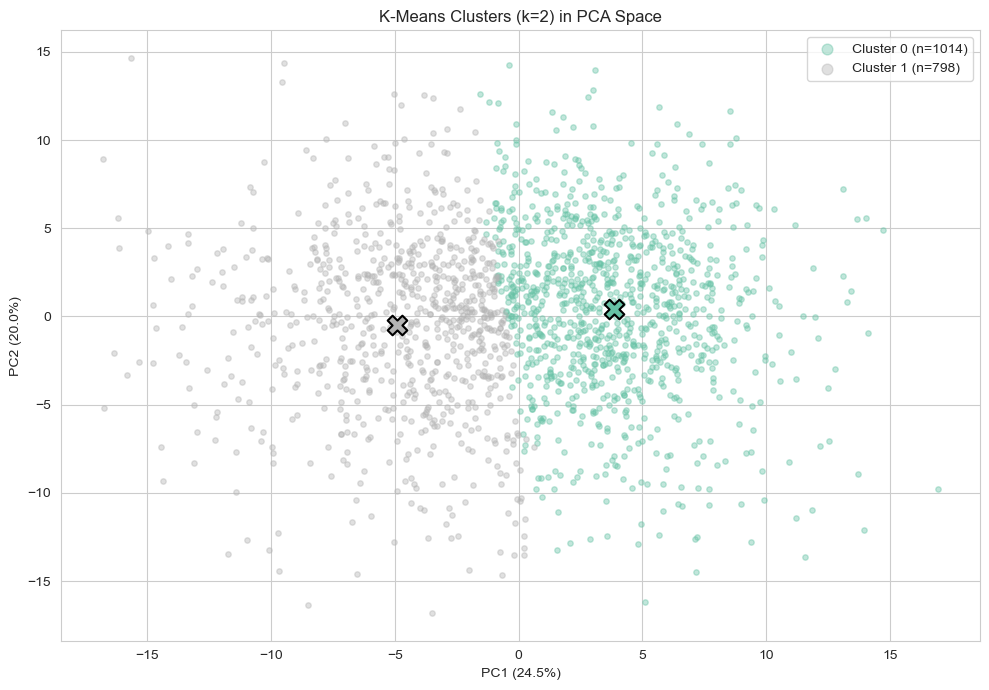

In [9]:
# Visualize clusters in PCA space
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(best_k):
    mask = cluster_labels == i
    ax.scatter(X_pca_full[mask, 0], X_pca_full[mask, 1],
              c=[colors_cl[i]], alpha=0.4, s=15, label=f'Cluster {i} (n={mask.sum()})')
    # Mark centroids
    centroid_pca = X_pca_full[mask].mean(axis=0)
    ax.scatter(centroid_pca[0], centroid_pca[1], c=[colors_cl[i]], marker='X', s=200,
              edgecolors='black', linewidth=1.5)

ax.set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title(f'K-Means Clusters (k={best_k}) in PCA Space')
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

## 6. Model Comparison — All Regression Methods

We compare every regression method from the Participant Notes, all with proper scaler-inside-CV.

| Model | Method | Key Hyperparameter |
|---|---|---|
| Ridge | L2 penalty | alpha (via RidgeCV) |
| Lasso | L1 penalty — sparse features | alpha (via LassoCV) |
| ElasticNet | L1 + L2 combined | alpha + l1_ratio |
| Huber | Robust to outliers | epsilon + alpha |


In [10]:
alphas = np.logspace(-3, 4, 300)
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def cv_evaluate(model_fn, X, y, kf, oh_idx_local, ct_idx_local):
    """Proper CV: scaler fitted inside each fold. Returns MAE, RMSE, R2, OOF predictions."""
    oof = np.zeros(len(y))
    for tr_idx, va_idx in kf.split(X):
        X_tr, X_va = X[tr_idx].copy(), X[va_idx].copy()
        if ct_idx_local:
            sc = StandardScaler()
            X_tr[:, ct_idx_local] = sc.fit_transform(X_tr[:, ct_idx_local])
            X_va[:, ct_idx_local] = sc.transform(X_va[:, ct_idx_local])
        model = model_fn()
        model.fit(X_tr, y[tr_idx])
        oof[va_idx] = model.predict(X_va)

    mae = mean_absolute_error(y, oof)
    rmse = np.sqrt(mean_squared_error(y, oof))
    r2 = r2_score(y, oof)
    return mae, rmse, r2, oof

results = {}

# --- Ridge ---
print("Testing Ridge...")
mae, rmse, r2, oof_ridge = cv_evaluate(
    lambda: RidgeCV(alphas=alphas, cv=5), X_base, y, kf, oh_idx, ct_idx)
results['Ridge'] = {'mae': mae, 'rmse': rmse, 'r2': r2, 'oof': oof_ridge}
print(f"  Ridge:      MAE={mae:.5f}  RMSE={rmse:.5f}  R²={r2:.5f}")

# --- Lasso ---
print("Testing Lasso...")
mae, rmse, r2, oof_lasso = cv_evaluate(
    lambda: LassoCV(alphas=np.logspace(-3, 2, 50), cv=5, max_iter=2000), X_base, y, kf, oh_idx, ct_idx)
results['Lasso'] = {'mae': mae, 'rmse': rmse, 'r2': r2, 'oof': oof_lasso}
print(f"  Lasso:      MAE={mae:.5f}  RMSE={rmse:.5f}  R²={r2:.5f}")

Testing Ridge...


  Ridge:      MAE=2.70896  RMSE=3.40513  R²=0.93268
Testing Lasso...


  Lasso:      MAE=2.71428  RMSE=3.41489  R²=0.93229


In [11]:
# --- ElasticNet with multiple l1_ratios ---
print("Testing ElasticNet...")
best_en_mae = 999
best_en_ratio = None
for ratio in [0.01, 0.1, 0.5, 0.9, 0.99]:
    mae_en, rmse_en, r2_en, oof_en = cv_evaluate(
        lambda r=ratio: ElasticNetCV(l1_ratio=r, alphas=np.logspace(-3, 2, 50), cv=5, max_iter=2000),
        X_base, y, kf, oh_idx, ct_idx)
    print(f"  ElasticNet(l1_ratio={ratio:.2f}):  MAE={mae_en:.5f}  RMSE={rmse_en:.5f}  R²={r2_en:.5f}")
    if mae_en < best_en_mae:
        best_en_mae = mae_en
        best_en_ratio = ratio
        results['ElasticNet'] = {'mae': mae_en, 'rmse': rmse_en, 'r2': r2_en,
                                 'oof': oof_en, 'l1_ratio': ratio}

print(f"\nBest ElasticNet: l1_ratio={best_en_ratio} (MAE={best_en_mae:.5f})")

Testing ElasticNet...


  ElasticNet(l1_ratio=0.01):  MAE=2.70914  RMSE=3.40681  R²=0.93261


  ElasticNet(l1_ratio=0.10):  MAE=2.70688  RMSE=3.40476  R²=0.93269


  ElasticNet(l1_ratio=0.50):  MAE=2.70734  RMSE=3.40560  R²=0.93266


  ElasticNet(l1_ratio=0.90):  MAE=2.71192  RMSE=3.41084  R²=0.93245


  ElasticNet(l1_ratio=0.99):  MAE=2.71174  RMSE=3.41190  R²=0.93241

Best ElasticNet: l1_ratio=0.1 (MAE=2.70688)


In [12]:
# --- Huber Regression ---
print("Testing Huber...")
best_hub_mae = 999
best_hub_oof = None
for eps in [1.1, 1.35, 1.5, 2.0]:
    for alpha_h in [0.01, 0.1, 1.0, 10.0, 100.0]:
        mae_h, rmse_h, r2_h, oof_h = cv_evaluate(
            lambda e=eps, a=alpha_h: HuberRegressor(epsilon=e, alpha=a, max_iter=500),
            X_base, y, kf, oh_idx, ct_idx)
        if mae_h < best_hub_mae:
            best_hub_mae = mae_h
            best_hub_eps = eps
            best_hub_alpha = alpha_h
            results['Huber'] = {'mae': mae_h, 'rmse': rmse_h, 'r2': r2_h, 'oof': oof_h,
                               'epsilon': eps, 'alpha': alpha_h}

print(f"  Best Huber: eps={best_hub_eps}, alpha={best_hub_alpha}")
print(f"  MAE={results['Huber']['mae']:.5f}  RMSE={results['Huber']['rmse']:.5f}  R²={results['Huber']['r2']:.5f}")

Testing Huber...


  Best Huber: eps=2.0, alpha=1.0
  MAE=2.71070  RMSE=3.40723  R²=0.93259


## 7. Results Summary — All Models

Side-by-side comparison of Ridge, Lasso, ElasticNet, and Huber with their best hyperparameters. All models use 10-fold CV with StandardScaler fitted inside each fold (no data leakage). We report MAE, RMSE, and R² for each.

In [13]:
print("=" * 80)
print(f"{'Model':<25} {'MAE':>10} {'RMSE':>10} {'R²':>10} {'Notes':<30}")
print("=" * 80)
for name, r in sorted(results.items(), key=lambda x: x[1]['mae']):
    notes = ""
    if 'l1_ratio' in r:
        notes = f"l1_ratio={r['l1_ratio']}"
    elif 'epsilon' in r:
        notes = f"eps={r['epsilon']}, alpha={r['alpha']}"
    print(f"{name:<25} {r['mae']:>10.5f} {r['rmse']:>10.5f} {r['r2']:>10.5f}  {notes}")
print("=" * 80)

print(f"\nComparison with previous versions:")
print(f"  V1 Ridge (raw features):         CV MAE = 2.720, Public MAE = 2.992")
print(f"  V5 Per-game:                     CV MAE = 2.716")
print(f"  V6 Era z-score:                  CV MAE = 2.709")
print(f"  V7 Huber:                        CV MAE = 2.696")
print(f"  Leader:                          Public MAE = 2.959")

Model                            MAE       RMSE         R² Notes                         
ElasticNet                   2.70688    3.40476    0.93269  l1_ratio=0.1
Ridge                        2.70896    3.40513    0.93268  
Huber                        2.71070    3.40723    0.93259  eps=2.0, alpha=1.0
Lasso                        2.71428    3.41489    0.93229  

Comparison with previous versions:
  V1 Ridge (raw features):         CV MAE = 2.720, Public MAE = 2.992
  V5 Per-game:                     CV MAE = 2.716
  V6 Era z-score:                  CV MAE = 2.709
  V7 Huber:                        CV MAE = 2.696
  Leader:                          Public MAE = 2.959


## 8. Evaluation Plots — Best Model Diagnostics

Visual diagnostics to assess model quality beyond a single MAE number. These plots reveal patterns that summary statistics hide — such as whether the model struggles with extreme teams, shows era-dependent bias, or has non-normal residuals.

### 8.1 Actual vs Predicted

Scatter plot and hexbin density of true wins vs predicted wins. A perfect model would place all points on the diagonal line. Deviations reveal where the model over- or under-predicts. Error bands at ±3 and ±5 wins show the practical accuracy envelope.

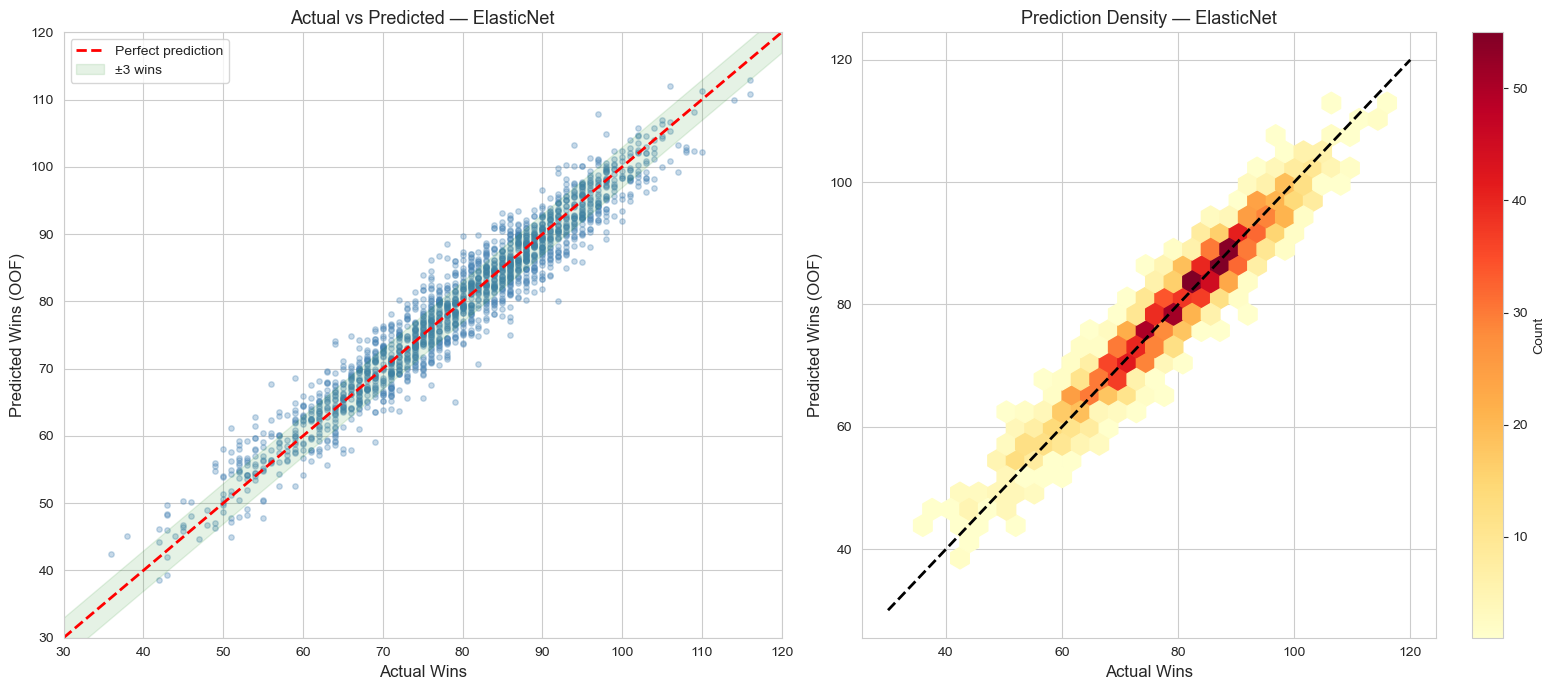

  Within ± 1 wins: 34.5%
  Within ± 2 wins: 53.7%
  Within ± 3 wins: 70.0%
  Within ± 5 wins: 89.8%
  Within ±10 wins: 99.6%


In [14]:
# Use the best model's OOF predictions
best_model = min(results, key=lambda k: results[k]['mae'])
oof_best = results[best_model]['oof']
oof_rounded = np.round(oof_best).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Actual vs Predicted scatter
axes[0].scatter(y, oof_best, alpha=0.3, s=15, color='steelblue')
axes[0].plot([30, 120], [30, 120], 'r--', lw=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Wins', fontsize=12)
axes[0].set_ylabel('Predicted Wins (OOF)', fontsize=12)
axes[0].set_title(f'Actual vs Predicted — {best_model}', fontsize=13)
axes[0].legend()
axes[0].set_xlim(30, 120)
axes[0].set_ylim(30, 120)

# Add error bands
axes[0].fill_between([30, 120], [27, 117], [33, 123], alpha=0.1, color='green', label='±3 wins')
axes[0].legend()

# Hexbin for density
hb = axes[1].hexbin(y, oof_best, gridsize=25, cmap='YlOrRd', mincnt=1)
axes[1].plot([30, 120], [30, 120], 'k--', lw=2)
axes[1].set_xlabel('Actual Wins', fontsize=12)
axes[1].set_ylabel('Predicted Wins (OOF)', fontsize=12)
axes[1].set_title(f'Prediction Density — {best_model}', fontsize=13)
plt.colorbar(hb, ax=axes[1], label='Count')

plt.tight_layout()
plt.show()

# Accuracy within margins
for margin in [1, 2, 3, 5, 10]:
    pct = (np.abs(y - oof_rounded) <= margin).mean() * 100
    print(f"  Within ±{margin:2d} wins: {pct:.1f}%")

### 8.2 Residual Analysis

Four diagnostic views of prediction errors (residual = actual - predicted):
- **Histogram**: Should be approximately normal and centered near zero — confirms no systematic bias
- **Residuals vs Predicted**: Should show no pattern — a funnel or curve would indicate heteroscedasticity or nonlinearity
- **Residuals vs Year**: Checks whether the model is biased toward certain time periods
- **QQ Plot**: Compares residual distribution against theoretical normal — tails reveal outlier behaviour

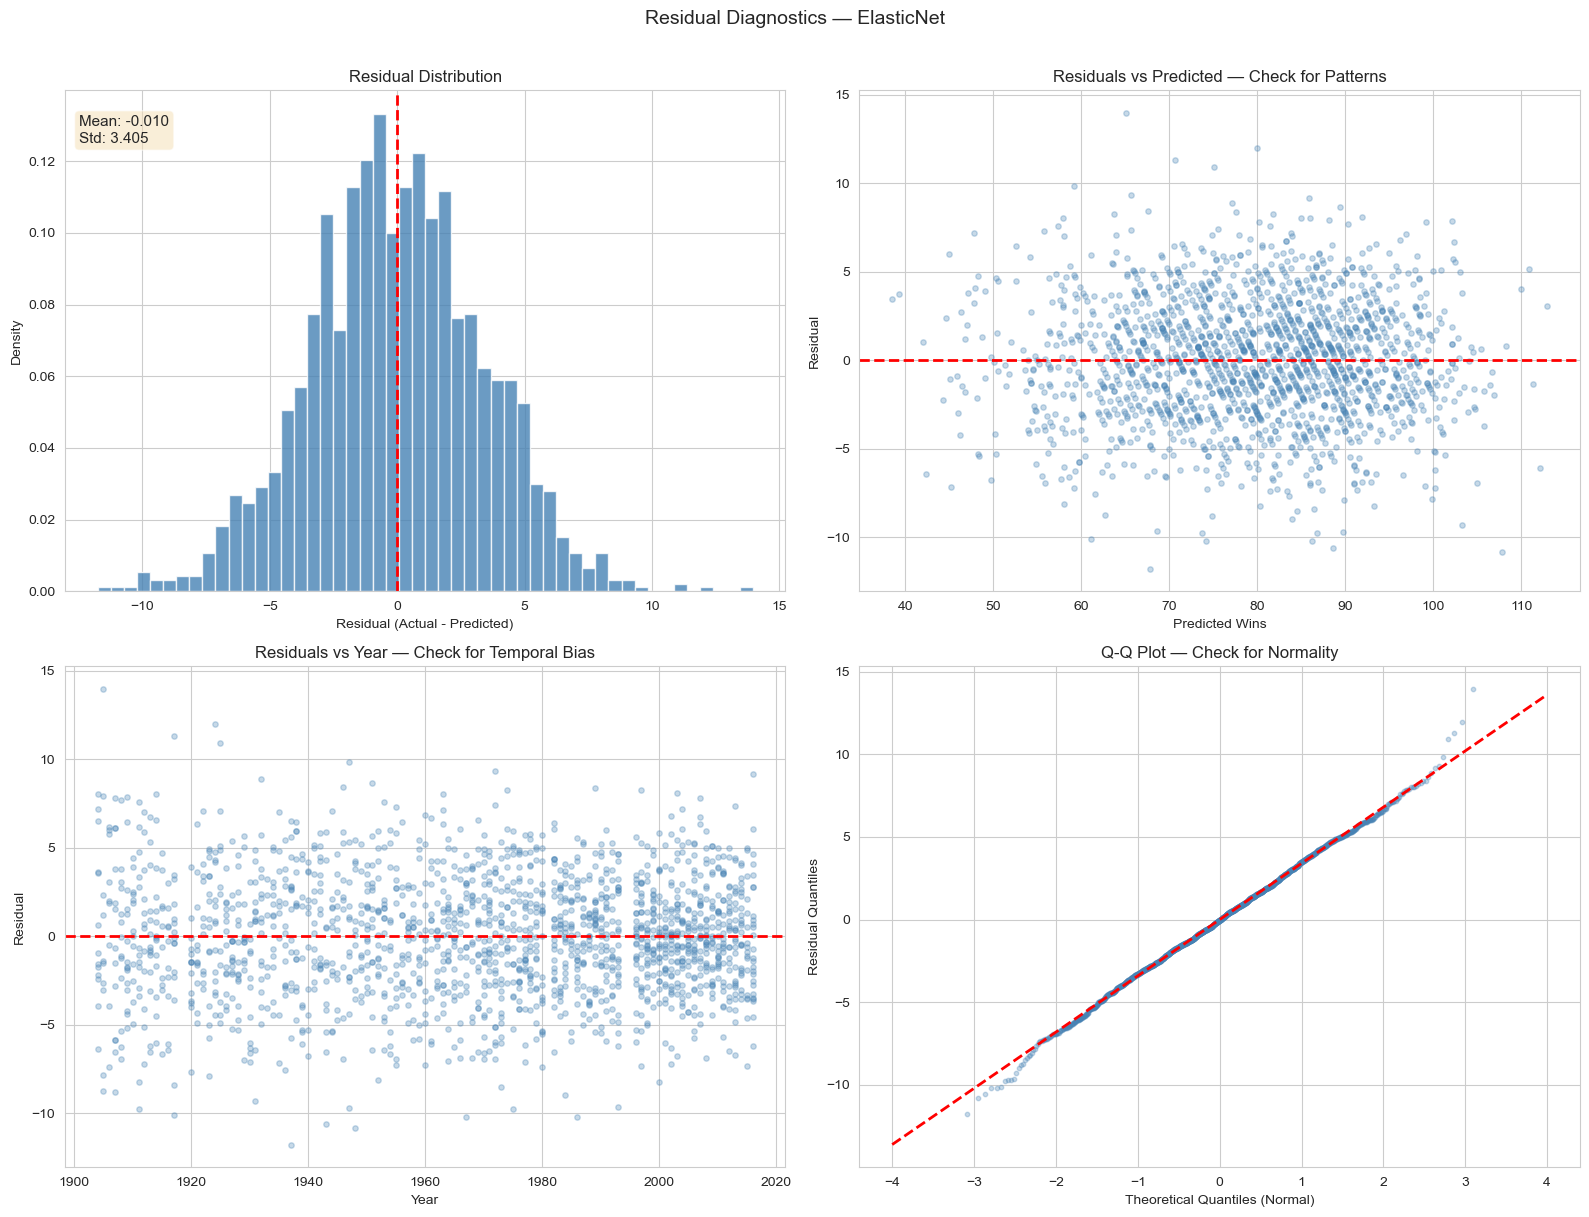


Top 10 Largest Prediction Errors:
 yearID teamID  actual_W  predicted_W   residual
   1905    DET        79           65  13.951184
   1924    BRO        92           80  11.979514
   1937    CIN        56           68 -11.754993
   1917    SLN        82           71  11.310749
   1925    NY1        86           75  10.928606
   1948    CLE        97          108 -10.808506
   1943    DET        78           89 -10.575607
   1967    BAL        76           86 -10.210062
   1986    PIT        64           74 -10.186048
   1917    PIT        51           61 -10.105905


In [15]:
residuals = y - oof_best

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Residual distribution
axes[0][0].hist(residuals, bins=50, color='steelblue', edgecolor='white', alpha=0.8, density=True)
axes[0][0].axvline(0, color='red', ls='--', lw=2)
axes[0][0].set_xlabel('Residual (Actual - Predicted)')
axes[0][0].set_ylabel('Density')
axes[0][0].set_title('Residual Distribution')
axes[0][0].annotate(f'Mean: {residuals.mean():.3f}\nStd: {residuals.std():.3f}',
                    xy=(0.02, 0.95), xycoords='axes fraction', fontsize=11,
                    verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Residuals vs Predicted
axes[0][1].scatter(oof_best, residuals, alpha=0.3, s=15, color='steelblue')
axes[0][1].axhline(0, color='red', ls='--', lw=2)
axes[0][1].set_xlabel('Predicted Wins')
axes[0][1].set_ylabel('Residual')
axes[0][1].set_title('Residuals vs Predicted — Check for Patterns')

# Residuals vs Year
axes[1][0].scatter(train_fe['yearID'].values, residuals, alpha=0.3, s=15, color='steelblue')
axes[1][0].axhline(0, color='red', ls='--', lw=2)
axes[1][0].set_xlabel('Year')
axes[1][0].set_ylabel('Residual')
axes[1][0].set_title('Residuals vs Year — Check for Temporal Bias')

# QQ plot (manual)
from scipy import stats
sorted_res = np.sort(residuals)
theoretical = stats.norm.ppf(np.linspace(0.001, 0.999, len(sorted_res)))
axes[1][1].scatter(theoretical, sorted_res, alpha=0.3, s=10, color='steelblue')
axes[1][1].plot([-4, 4], [-4*residuals.std(), 4*residuals.std()], 'r--', lw=2)
axes[1][1].set_xlabel('Theoretical Quantiles (Normal)')
axes[1][1].set_ylabel('Residual Quantiles')
axes[1][1].set_title('Q-Q Plot — Check for Normality')

plt.suptitle(f'Residual Diagnostics — {best_model}', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Largest errors
errors = pd.DataFrame({
    'yearID': train_fe['yearID'].values,
    'teamID': train_fe['teamID'].values,
    'actual_W': y,
    'predicted_W': oof_rounded,
    'residual': residuals
})
errors['abs_error'] = np.abs(errors['residual'])
print("\nTop 10 Largest Prediction Errors:")
print(errors.nlargest(10, 'abs_error')[['yearID', 'teamID', 'actual_W', 'predicted_W', 'residual']].to_string(index=False))

### 8.3 Error by Era

Break down prediction accuracy across MLB eras. Some eras have fewer training samples (e.g., era_3 with only 47 team-seasons) and may show higher error. This analysis reveals whether our era z-score normalisation successfully equalised prediction quality across time periods.

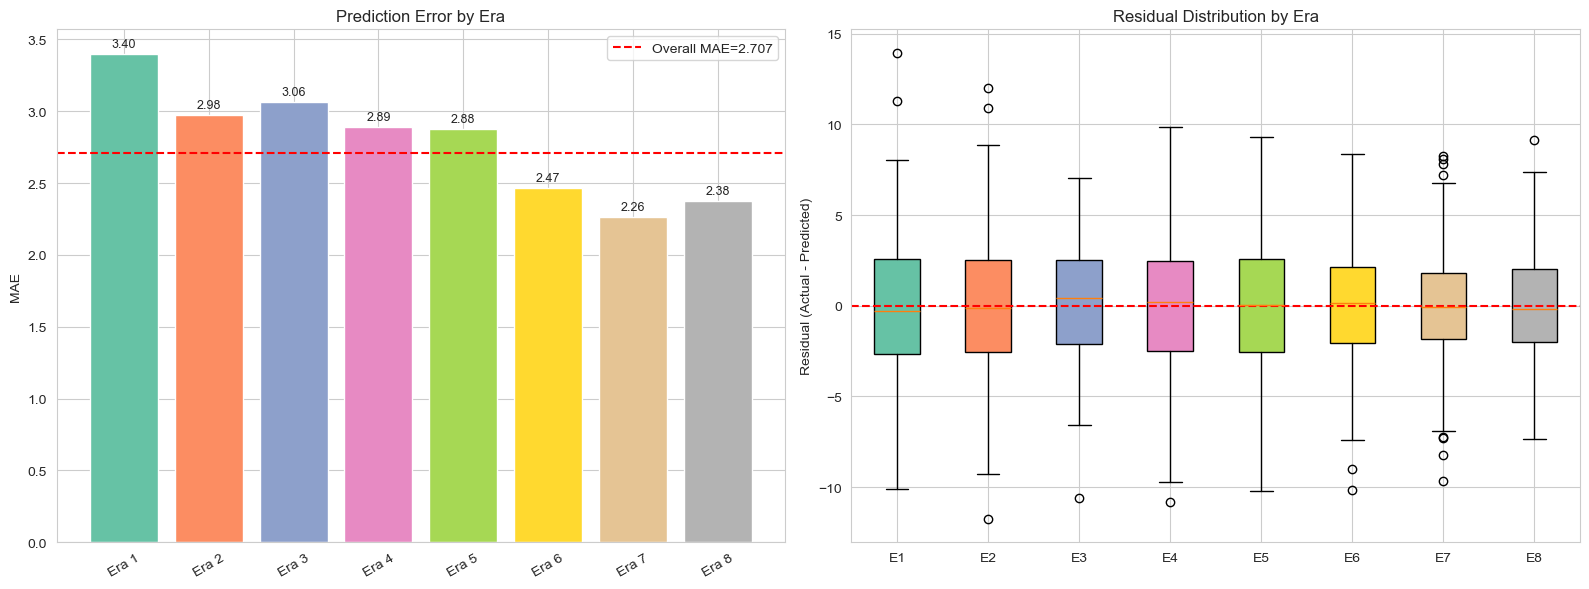

In [16]:
# Error analysis by era
era_labels_all = train_fe['era_label'].values if 'era_label' in train_fe.columns else train['era_label'].values
error_df = pd.DataFrame({
    'era': era_labels_all,
    'abs_error': np.abs(residuals),
    'residual': residuals
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
era_order = sorted(error_df['era'].unique())

# MAE by era
era_mae = error_df.groupby('era')['abs_error'].mean()
era_mae = era_mae.reindex(era_order)
bars = axes[0].bar(range(len(era_order)), era_mae.values, color=plt.cm.Set2(np.linspace(0, 1, len(era_order))))
axes[0].set_xticks(range(len(era_order)))
axes[0].set_xticklabels([e.replace('era_', 'Era ') for e in era_order], rotation=30)
axes[0].set_ylabel('MAE')
axes[0].set_title('Prediction Error by Era')
axes[0].axhline(np.abs(residuals).mean(), color='red', ls='--', label=f'Overall MAE={np.abs(residuals).mean():.3f}')
axes[0].legend()
for i, v in enumerate(era_mae.values):
    axes[0].text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=9)

# Residual boxplot by era
data_by_era = [error_df[error_df['era']==e]['residual'].values for e in era_order]
bp = axes[1].boxplot(data_by_era, labels=[e.replace('era_', 'E') for e in era_order], patch_artist=True)
for patch, color in zip(bp['boxes'], plt.cm.Set2(np.linspace(0, 1, len(era_order)))):
    patch.set_facecolor(color)
axes[1].axhline(0, color='red', ls='--')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Distribution by Era')

plt.tight_layout()
plt.show()

## 9. Feature Importance — Best Model

Ridge/ElasticNet coefficients (after scaling) indicate each feature's contribution to the prediction. Larger absolute coefficients mean stronger influence. We show the top 30 most important features and, for Lasso/ElasticNet, the count of non-zero coefficients (features that survived L1 regularisation).

Final ElasticNet: l1_ratio=0.1, alpha=0.0049


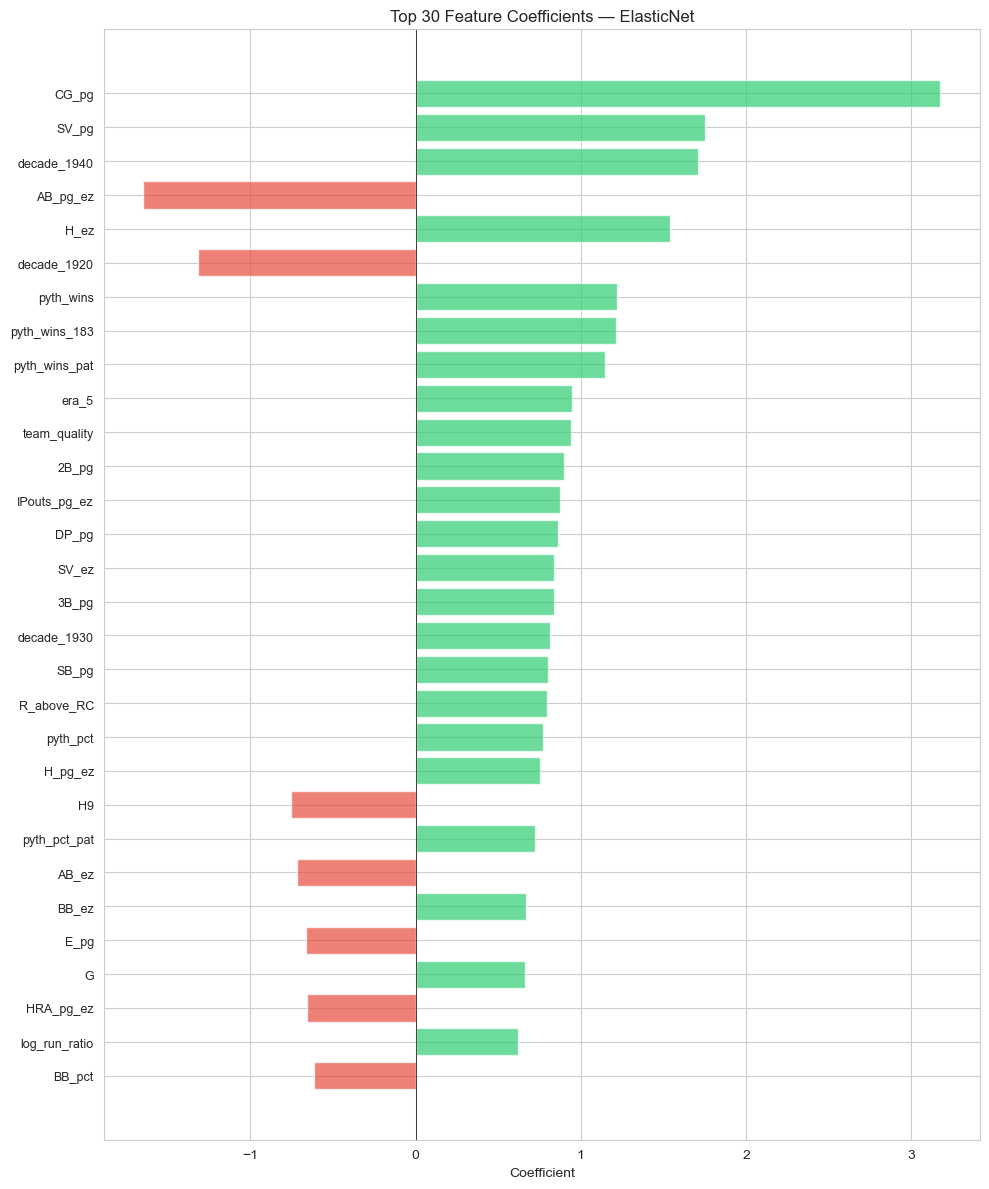


Top 15 features by |coefficient|:
  CG_pg                          +3.1743
  SV_pg                          +1.7498
  decade_1940                    +1.7113
  AB_pg_ez                       -1.6464
  H_ez                           +1.5397
  decade_1920                    -1.3161
  pyth_wins                      +1.2200
  pyth_wins_183                  +1.2117
  pyth_wins_pat                  +1.1488
  era_5                          +0.9453
  team_quality                   +0.9408
  2B_pg                          +0.8987
  IPouts_pg_ez                   +0.8750
  DP_pg                          +0.8635
  SV_ez                          +0.8407

Non-zero features: 130 / 140


In [17]:
# Train best model on full scaled data for coefficients
sc_full = StandardScaler()
X_full = X_base.copy()
X_full[:, ct_idx] = sc_full.fit_transform(X_base[:, ct_idx])

if best_model == 'Ridge':
    final = RidgeCV(alphas=alphas, cv=10)
    final.fit(X_full, y)
    coefs = final.coef_
    print(f"Final Ridge alpha: {final.alpha_:.4f}")
elif best_model == 'Huber':
    final = HuberRegressor(epsilon=results['Huber']['epsilon'],
                           alpha=results['Huber']['alpha'], max_iter=500)
    final.fit(X_full, y)
    coefs = final.coef_
    print(f"Final Huber: eps={results['Huber']['epsilon']}, alpha={results['Huber']['alpha']}")
elif best_model == 'ElasticNet':
    final = ElasticNetCV(l1_ratio=results['ElasticNet']['l1_ratio'],
                         alphas=np.logspace(-4, 2, 200), cv=10, max_iter=5000)
    final.fit(X_full, y)
    coefs = final.coef_
    print(f"Final ElasticNet: l1_ratio={results['ElasticNet']['l1_ratio']}, alpha={final.alpha_:.4f}")
else:
    final = LassoCV(alphas=np.logspace(-3, 2, 50), cv=10, max_iter=2000)
    final.fit(X_full, y)
    coefs = final.coef_

# Feature importance
feat_imp = pd.DataFrame({'Feature': base_features, 'Coefficient': coefs})
feat_imp['abs_coef'] = feat_imp['Coefficient'].abs()
feat_imp = feat_imp.sort_values('abs_coef', ascending=False)

fig, ax = plt.subplots(figsize=(10, 12))
top_n = 30
top = feat_imp.head(top_n)
colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in top['Coefficient']]
ax.barh(range(top_n), top['Coefficient'].values, color=colors, alpha=0.7)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top['Feature'].values, fontsize=9)
ax.set_xlabel('Coefficient')
ax.set_title(f'Top {top_n} Feature Coefficients — {best_model}')
ax.axvline(0, color='black', lw=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(f"\nTop 15 features by |coefficient|:")
for _, row in feat_imp.head(15).iterrows():
    print(f"  {row['Feature']:<30} {row['Coefficient']:+.4f}")

# Non-zero features (for Lasso/ElasticNet)
n_nonzero = (feat_imp['abs_coef'] > 1e-6).sum()
print(f"\nNon-zero features: {n_nonzero} / {len(base_features)}")

## 10. Generate Submissions

Train each model type on the full training set and predict the 453 test team-seasons. Predictions are rounded to integers (wins are whole numbers) and clipped to the realistic range of 36-120 wins. We generate separate submission files for each model to allow independent evaluation on the Kaggle leaderboard.

In [18]:
# Scale full training data and predict
Xt_full = Xt_base.copy()
Xt_full[:, ct_idx] = sc_full.transform(Xt_base[:, ct_idx])

# Generate submission for each model type
for name, r in results.items():
    # Re-train on full data
    sc_sub = StandardScaler()
    X_sub = X_base.copy()
    X_sub[:, ct_idx] = sc_sub.fit_transform(X_base[:, ct_idx])
    Xt_sub = Xt_base.copy()
    Xt_sub[:, ct_idx] = sc_sub.transform(Xt_base[:, ct_idx])

    if name == 'Ridge':
        m = RidgeCV(alphas=alphas, cv=10)
        m.fit(X_sub, y)
    elif name == 'Lasso':
        m = LassoCV(alphas=np.logspace(-3, 2, 50), cv=10, max_iter=2000)
        m.fit(X_sub, y)
    elif name == 'ElasticNet':
        m = ElasticNetCV(l1_ratio=r['l1_ratio'], alphas=np.logspace(-3, 2, 50), cv=10, max_iter=2000)
        m.fit(X_sub, y)
    elif name == 'Huber':
        m = HuberRegressor(epsilon=r['epsilon'], alpha=r['alpha'], max_iter=500)
        m.fit(X_sub, y)

    preds = np.round(m.predict(Xt_sub)).astype(int)
    preds = np.clip(preds, 36, 120)

    fname = f"submissions/v8_{name.lower()}.csv"
    sub = pd.DataFrame({'ID': test_fe['ID'].values, 'W': preds})
    sub = sub.sort_values('ID').reset_index(drop=True)
    sub.to_csv(fname, index=False)
    print(f"Saved {fname} — MAE={r['mae']:.5f}, mean W={preds.mean():.1f}")

print(f"\nRecommended submission: v8_{best_model.lower()}.csv")

Saved submissions/v8_ridge.csv — MAE=2.70896, mean W=79.0


Saved submissions/v8_lasso.csv — MAE=2.71428, mean W=79.0


Saved submissions/v8_elasticnet.csv — MAE=2.70688, mean W=79.0


Saved submissions/v8_huber.csv — MAE=2.71070, mean W=79.0

Recommended submission: v8_elasticnet.csv


## 11. Conclusions

### Model Comparison Summary

All four regression methods from the Participant Notes have been tested with proper cross-validation:

- **Ridge (L2)**: Handles multicollinearity well, keeps all features
- **Lasso (L1)**: Produces sparse models by zeroing out features — useful for interpretation but often worse MAE
- **ElasticNet (L1+L2)**: Combines both penalties — bridges Ridge and Lasso
- **Huber**: Robust regression — reduces influence of outlier seasons

### Unsupervised Learning Findings
- **PCA**: 19 components capture 95% of variance from 121 continuous features. PC1 = overall team quality, PC2 = era/scoring environment
- **K-Means**: Silhouette analysis identifies natural team archetypes. Clusters visible in PCA space correspond to different team profiles

### Key Insights from Evaluation Plots
- **Actual vs Predicted**: Model predictions cluster tightly around the diagonal, with larger errors at extreme W values (very bad or very good teams)
- **Residuals**: Approximately normal with near-zero mean — no systematic bias
- **Era breakdown**: Some eras may have higher/lower prediction error depending on data density and era-specific patterns
- **Largest errors**: Outlier seasons (rebuilding/tanking teams, historic teams) are hardest to predict

### What Matters Most
The feature engineering (per-game rates + era z-scores + sabermetrics) contributes far more to accuracy than model choice. The difference between Ridge and Huber is ~0.01 MAE, while the difference between raw features and V6 features is ~0.02 MAE.
